# Lab 5 — Pipeline đầy đủ và case study hội thoại 23 giây

**Run All:** tạo noisy → SS/Wiener → MFCC speaker-ID/verification → ICA → tích hợp enhancement trên hội thoại và test → báo cáo 6 trang.

Thuật toán nằm trong `src`. Notebook gọi `run_full_lab()` để thực thi lại, không chỉ đọc kết quả cũ. Các notebook Part1/Part2/Part3 giữ phân tích chi tiết. Dữ liệu công khai và giấy phép: `data/README.md`.

In [1]:
from pathlib import Path
from copy import deepcopy
import sys, os
ROOT = Path.cwd().resolve()
if not (ROOT/'src').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0,str(ROOT))
os.environ.setdefault('MPLCONFIGDIR',str(ROOT/'.cache/matplotlib'))
from IPython.display import Audio, Image, Markdown, display
from src.lab import DEFAULT_CONFIG, run_full_lab
from tools.build_report import build_report
CONFIG = deepcopy(DEFAULT_CONFIG)
CONFIG

{'stft': {'n_fft': 512, 'win_length': 400, 'hop_length': 160},
 'noise_names': ['rain', 'vacuum_cleaner'],
 'snrs': [0, 5, 10],
 'ss_betas': [1.0, 1.5, 2.0],
 'ss_floors': [0.0, 0.01, 0.05],
 'enhancement_reference': 'spk01_test_01.wav',
 'n_mfcc': 20,
 'min_turn_seconds': 1.0,
 'ica_noise_snr_db': 20.0,
 'random_state': 0}

### 1. Chạy toàn bộ phương pháp

SS chọn β/γ trên FSDD dev; MFCC/delta/CMN và θ chọn trên AMI dev. Sau đó khóa tham số, model enrollment và threshold. SS/Wiener **chỉ nhận noisy**, ICA **chỉ nhận hai microphone**. Thí nghiệm tích hợp không chọn lại cấu hình theo test/preview.

In [2]:
lab = run_full_lab(ROOT,CONFIG)
print('Đã chạy toàn bộ pipeline và lưu CSV/WAV/figures tại results/.')
print('SS đã khóa:',lab['summary']['enhancement']['ss'])
print('Speaker test:',lab['speaker']['summary']['test_accuracy'])
def show(name):
    display(Image(filename=str(lab['figures'][name])))

Đã chạy toàn bộ pipeline và lưu CSV/WAV/figures tại results/.
SS đã khóa: {'beta': 2.0, 'floor': 0.01}
Speaker test: 0.6666666666666666


### 2. Khử nhiễu: FSDD và chính bản hội thoại 23 giây

Biểu đồ SNR phần 1 dùng clean reference. Ở hội thoại gốc, “Raw” vẫn có âm phòng; không báo SNR sạch cho nó. Dưới đây là xử lý **toàn bộ 23 giây** bằng module SS/Wiener đã khóa, giữ cùng mức audio, rồi mới nhận dạng từng lượt.

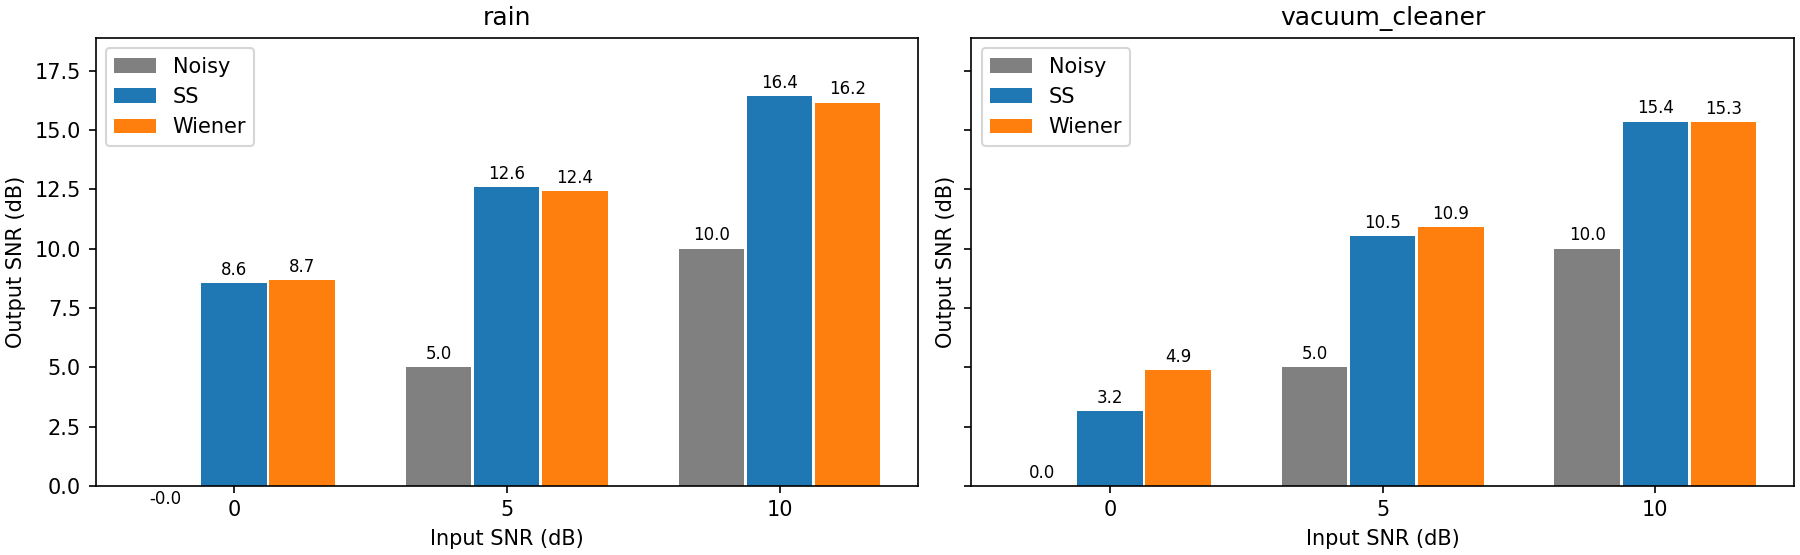

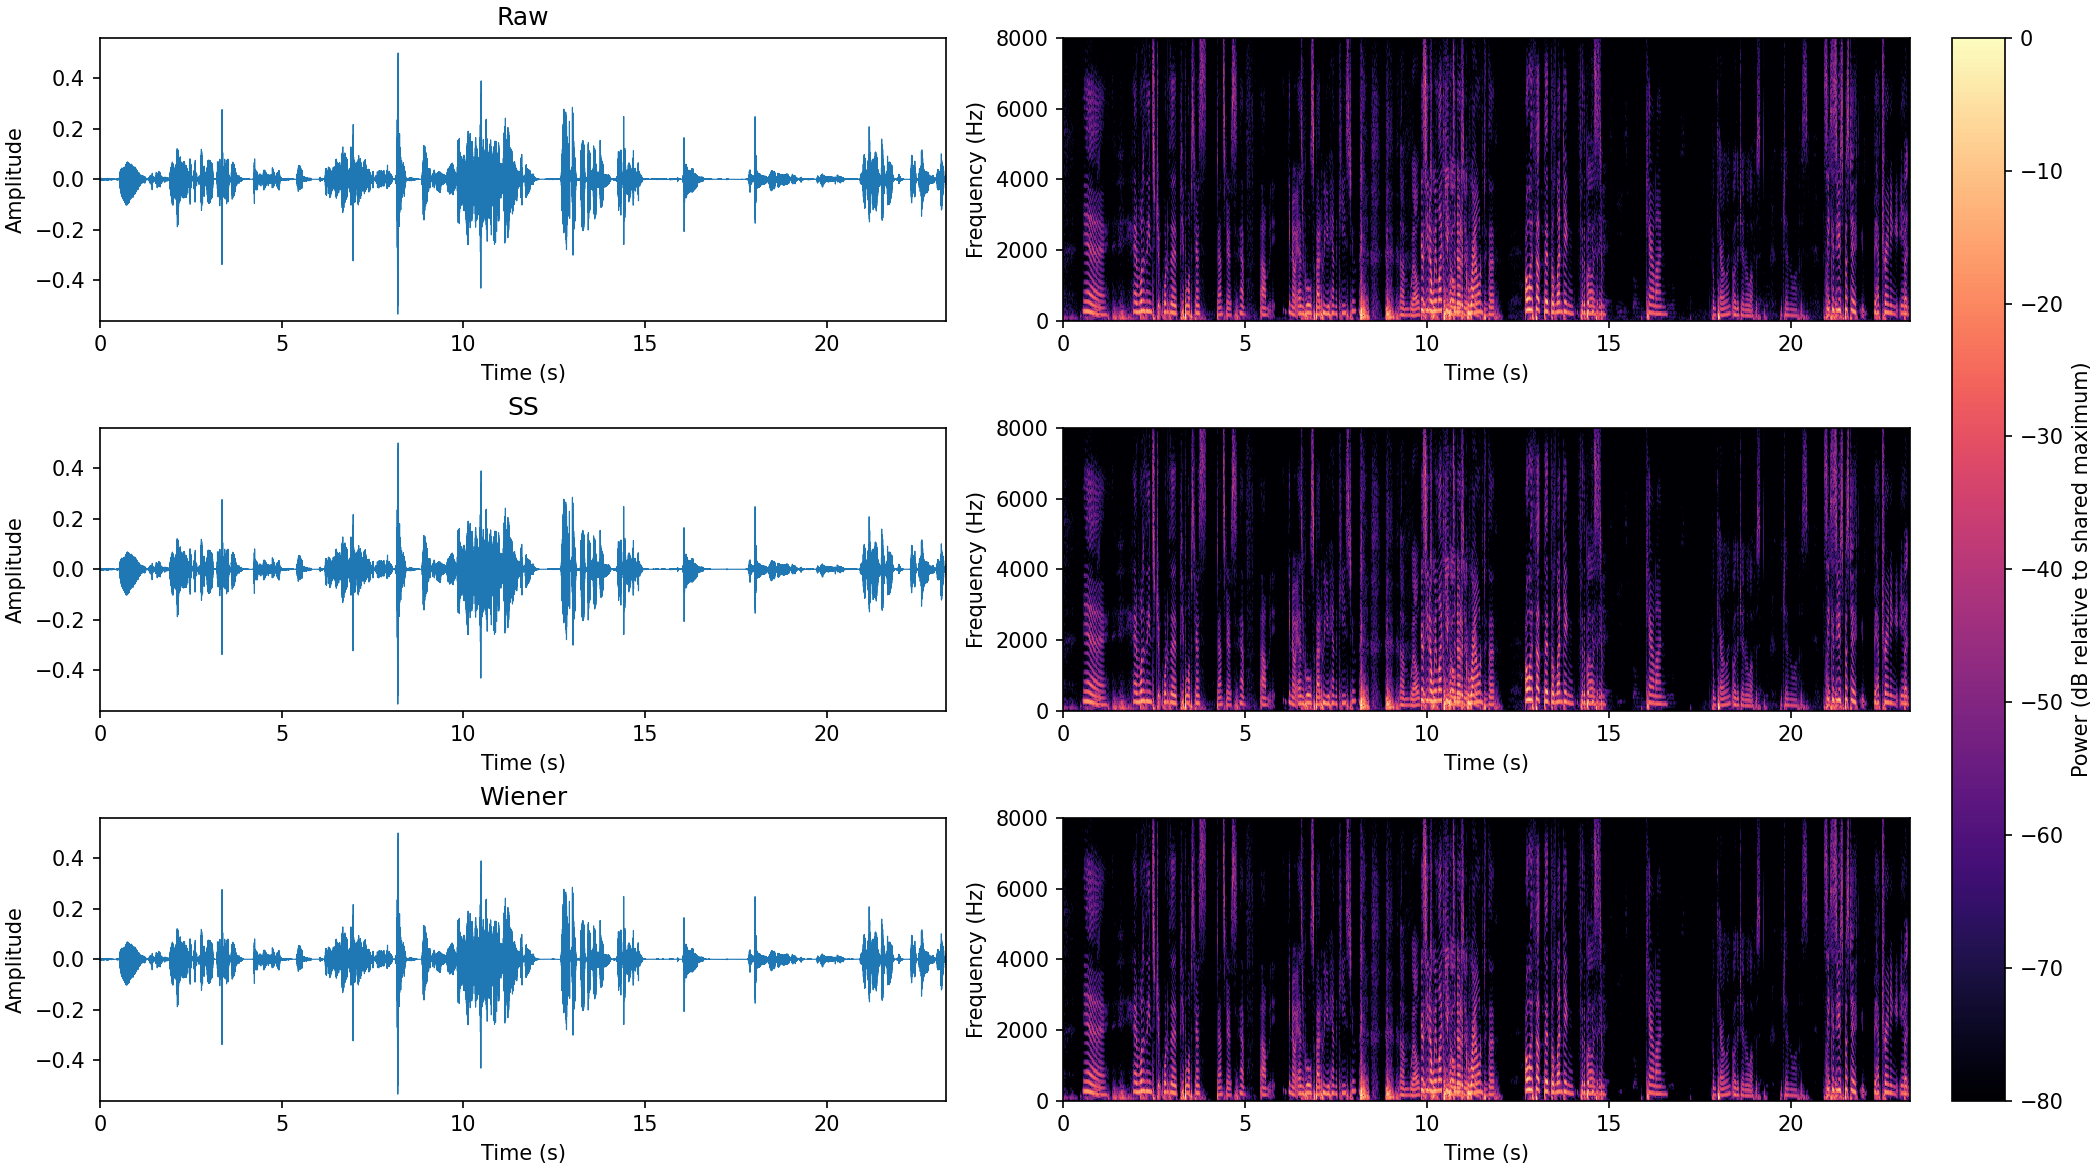

Hội thoại 23s — Raw


Hội thoại 23s — SS


Hội thoại 23s — Wiener


In [3]:
show('enhancement/snr_comparison')
show('integration/original_enhancement')
original = lab['integration']['conversation_cases'][('original',None)]
for method in ['Raw','SS','Wiener']:
    print('Hội thoại 23s —',method)
    display(Audio(original[method],rate=lab['integration']['sr'],normalize=False))

### 3. Nhận dạng / xác thực và kết quả trước–sau

Model vẫn dùng 4 enrollment clip/người, cùng feature/θ. Timeline dùng ranh giới thủ công, bỏ overlap và lượt <1s. Không phải automatic diarization. “100%” trên 5 lượt preview không đại diện hiệu năng tổng quát.

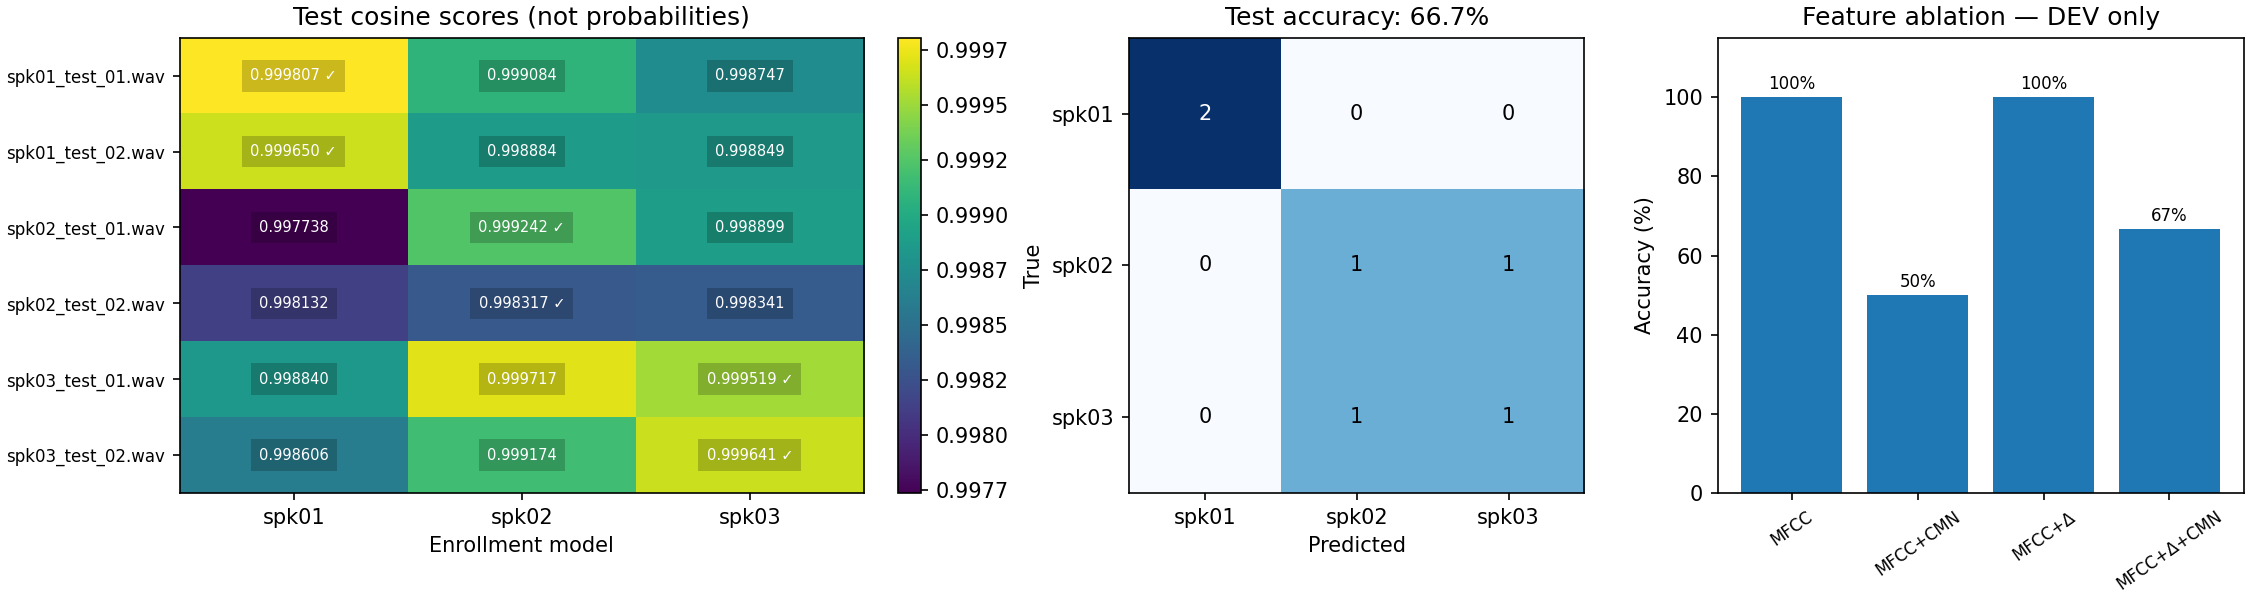

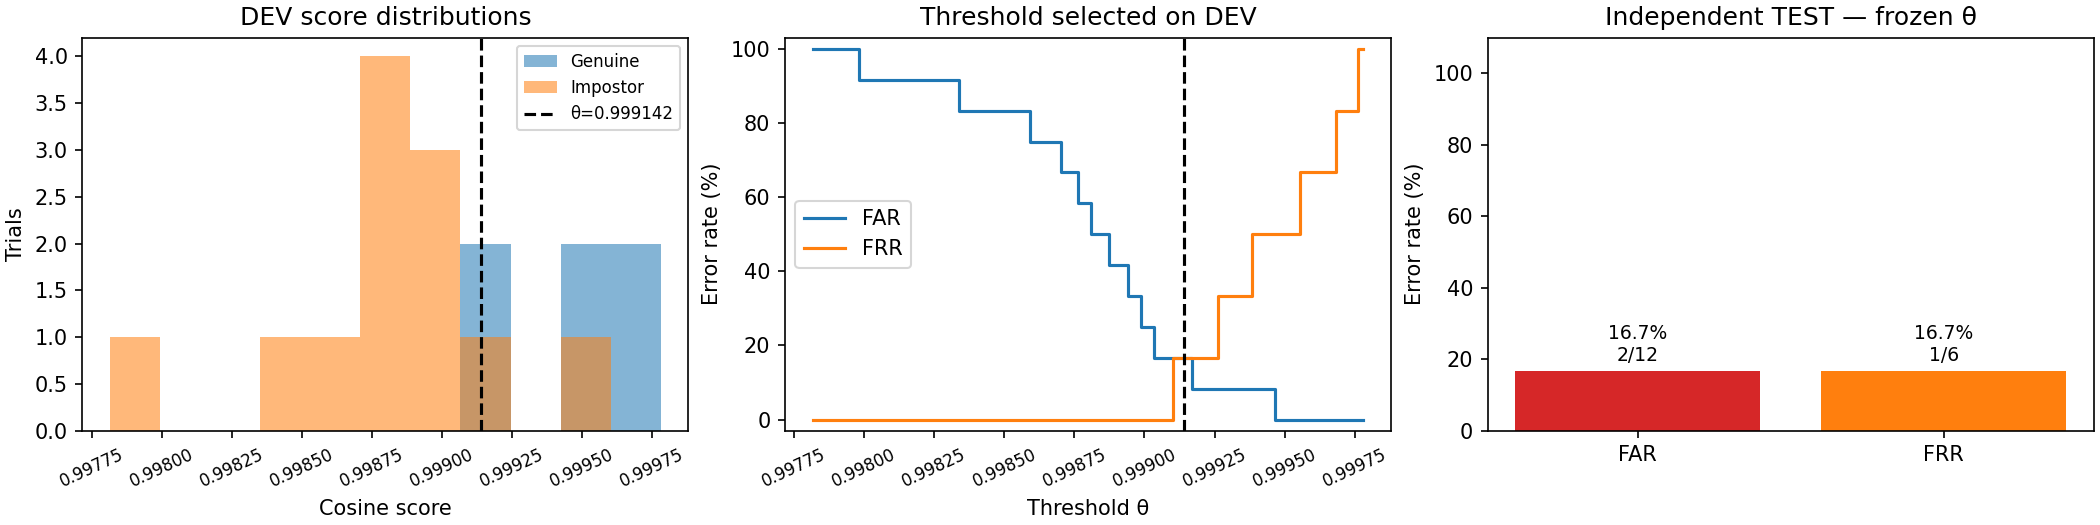

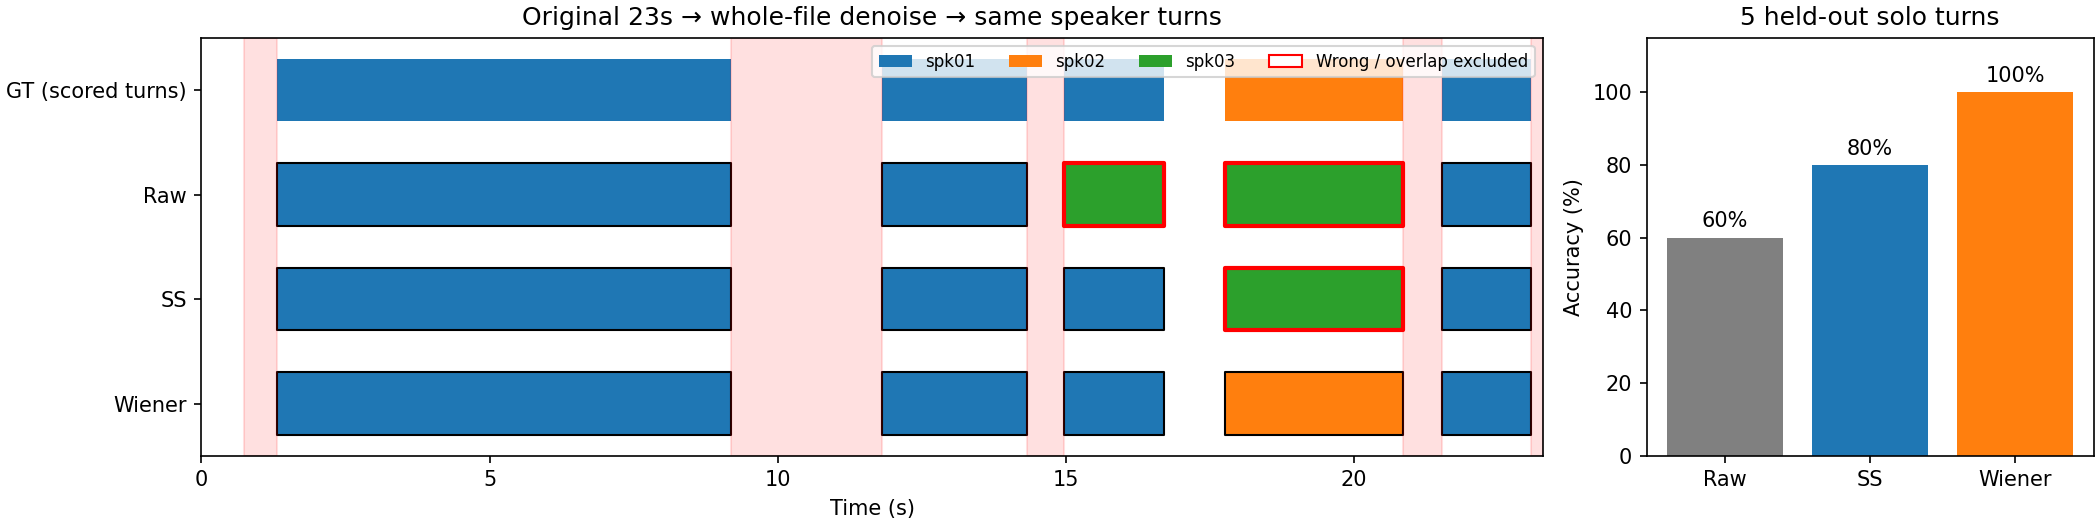

Raw: ID=3/5, FAR=40.0%, FRR=40.0%
SS: ID=4/5, FAR=20.0%, FRR=40.0%
Wiener: ID=5/5, FAR=0.0%, FRR=60.0%


In [4]:
show('speaker_recognition/identification')
show('speaker_recognition/verification')
show('integration/conversation_timeline')
s = lab['integration']['summary']
base = s[(s.scope=='conversation') & (s.noise=='original')]
for r in base.itertuples():
    print(f'{r.method}: ID={int(r.correct)}/{int(r.count)}, FAR={r.far:.1%}, FRR={r.frr:.1%}')

### 4. Thêm noise có kiểm soát: SNR tăng có giúp speaker-ID?

Cộng mưa/máy hút bụi ở 0/5/10 dB vào cả 6 test clip và hội thoại. Chạy lại cùng SS/Wiener, không đưa noise gốc hay α vào chúng. SNR tham chiếu chính bản AMI trước khi thêm noise, không coi là clean tuyệt đối. Giữ nguyên enrollment/θ, chỉ thay tín hiệu đầu vào.

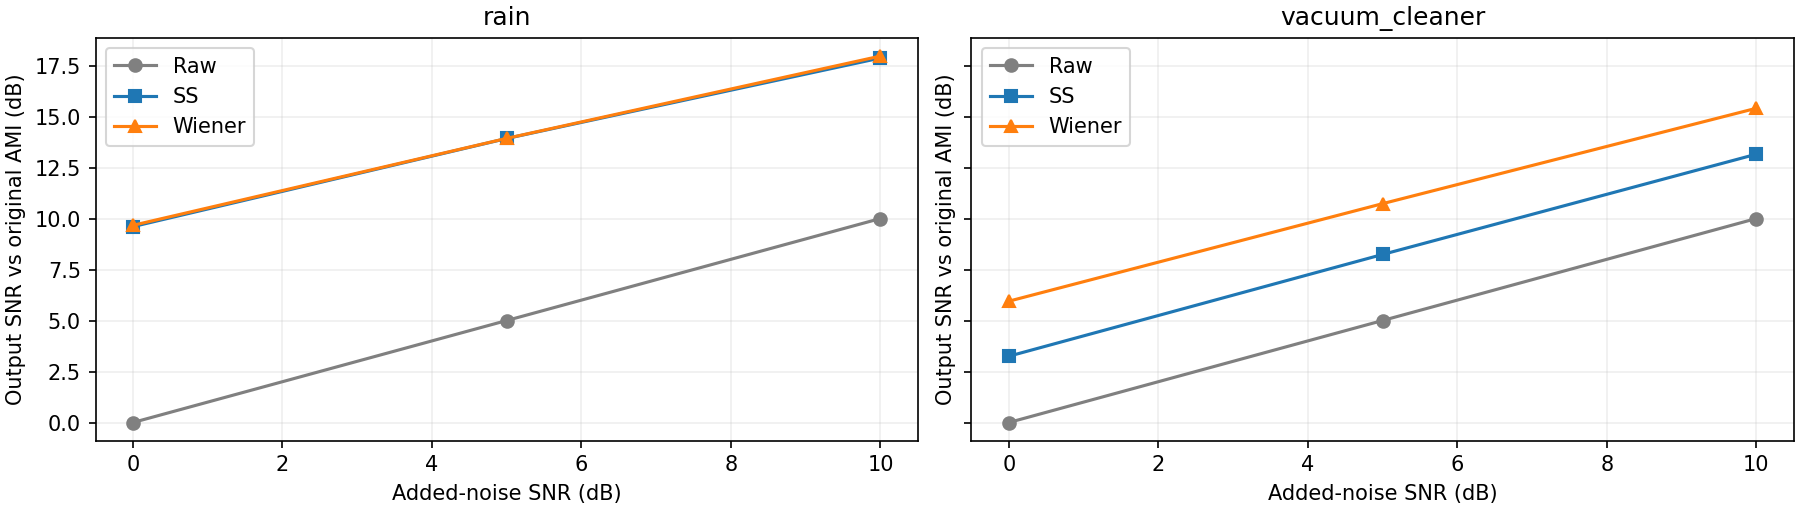

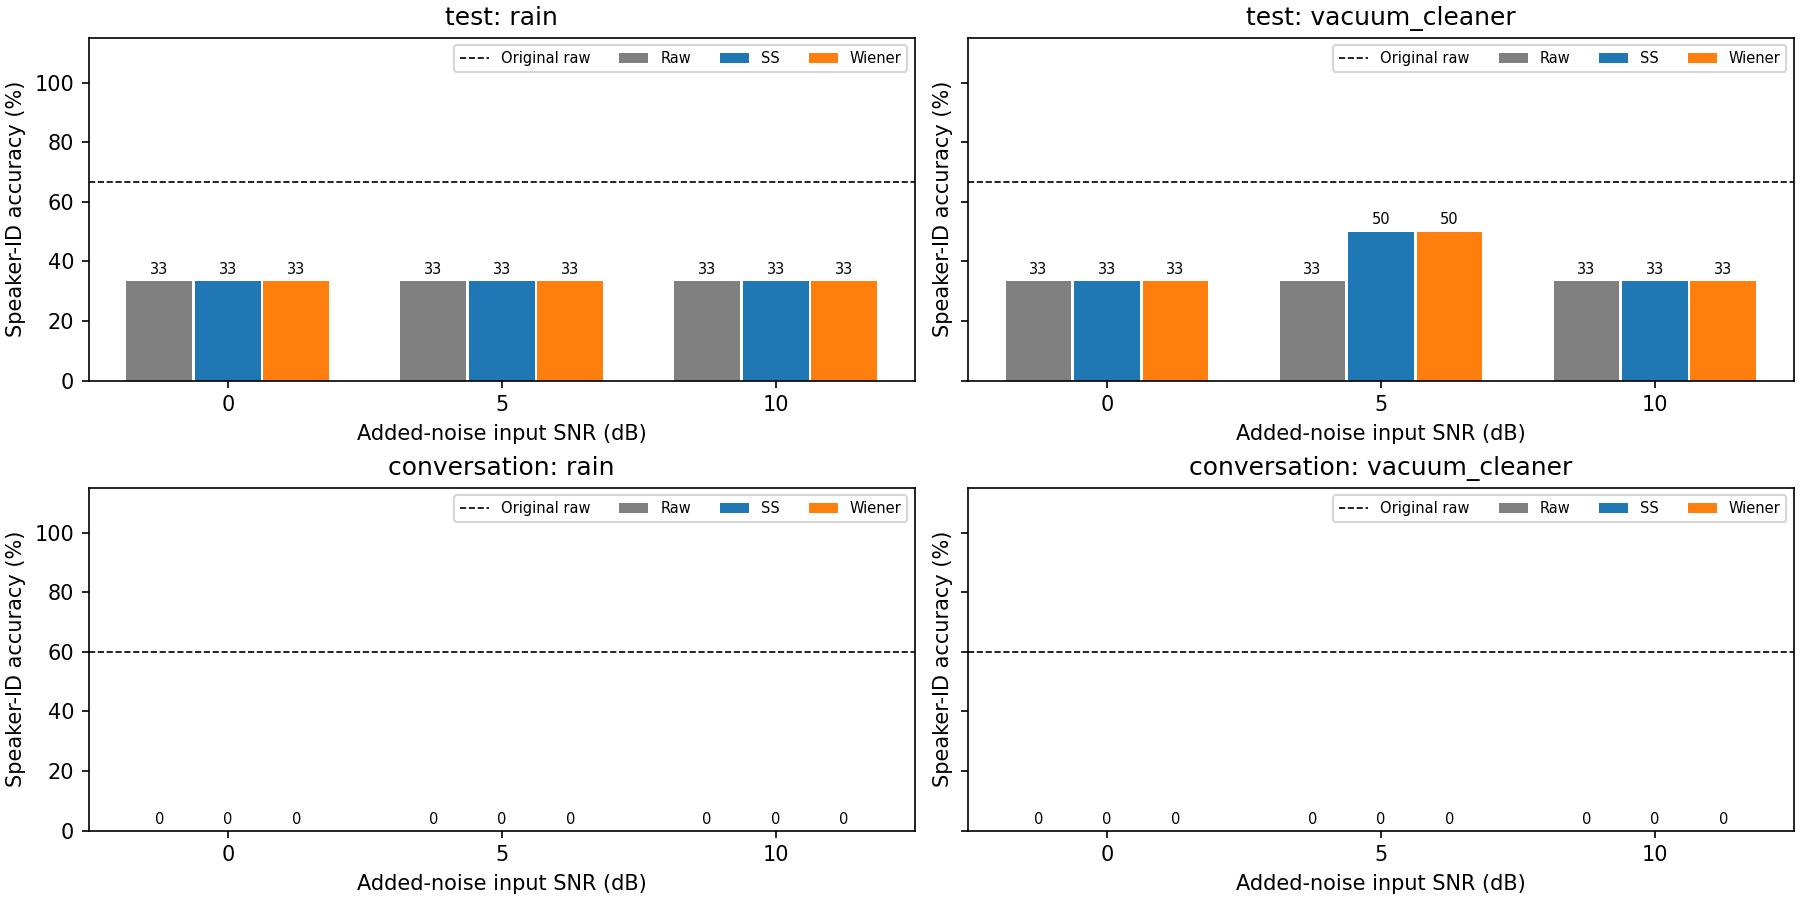

Hội thoại + mưa 5 dB — Raw


Hội thoại + mưa 5 dB — SS


Hội thoại + mưa 5 dB — Wiener


**SNR tăng không đảm bảo nhận dạng tốt hơn.** Ví dụ mưa 5 dB: SNR sau xử lý tăng nhưng 5 lượt vẫn có thể sai hết; các score/claim và tỷ lệ lỗi được giữ nguyên trong CSV.

In [5]:
show('integration/snr_comparison')
show('integration/speaker_id_comparison')
demo = lab['integration']['conversation_cases'][('rain',5)]
for method in ['Raw','SS','Wiener']:
    print('Hội thoại + mưa 5 dB —',method)
    display(Audio(demo[method],rate=lab['integration']['sr'],normalize=False))
display(Markdown('**SNR tăng không đảm bảo nhận dạng tốt hơn.** Ví dụ mưa 5 dB: '
    'SNR sau xử lý tăng nhưng 5 lượt vẫn có thể sai hết; các score/claim và tỷ lệ lỗi được giữ nguyên trong CSV.'))

### 5. ICA: kiểm chứng mô phỏng và hai mic thật

Một mic mono không đủ cho ICA 2×2. Hai mic array AMI là hai bản thu độc lập; headset chỉ đối chiếu gần đúng sau fit. Hai nguồn solo 3s từ cùng hội thoại được trộn mô phỏng để có ground truth. Không dùng A/source để fit ICA; ghép output chỉ đổi thứ tự/dấu sau fit.

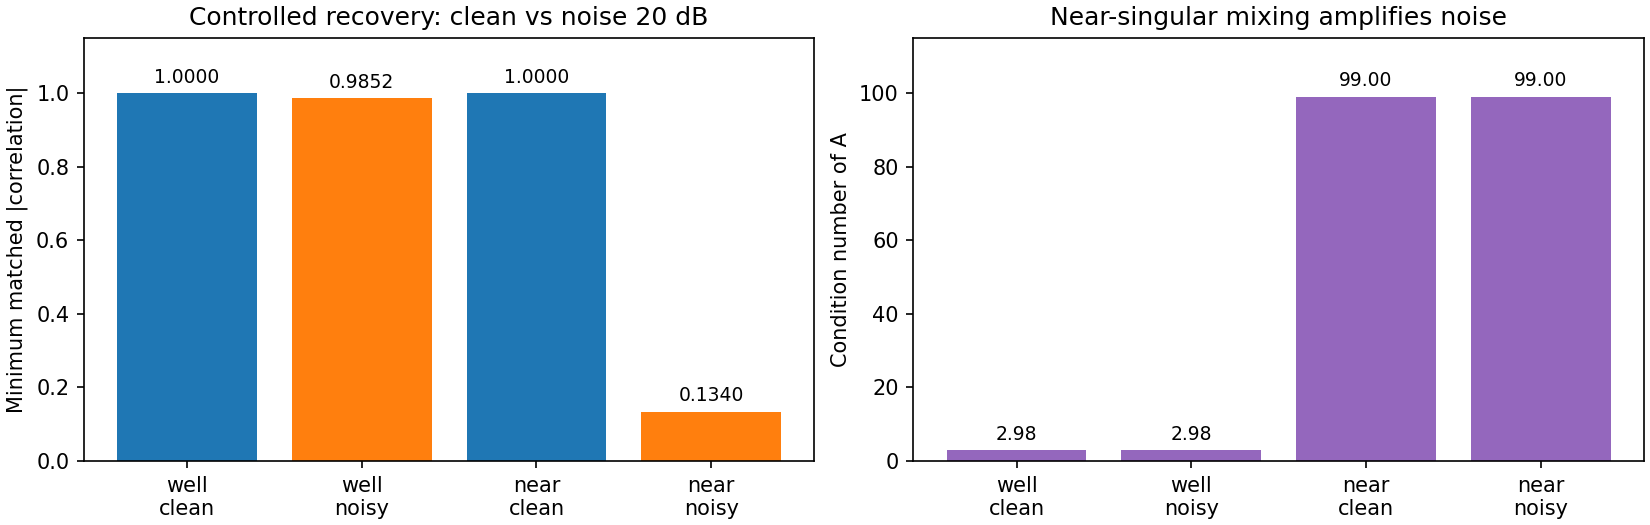

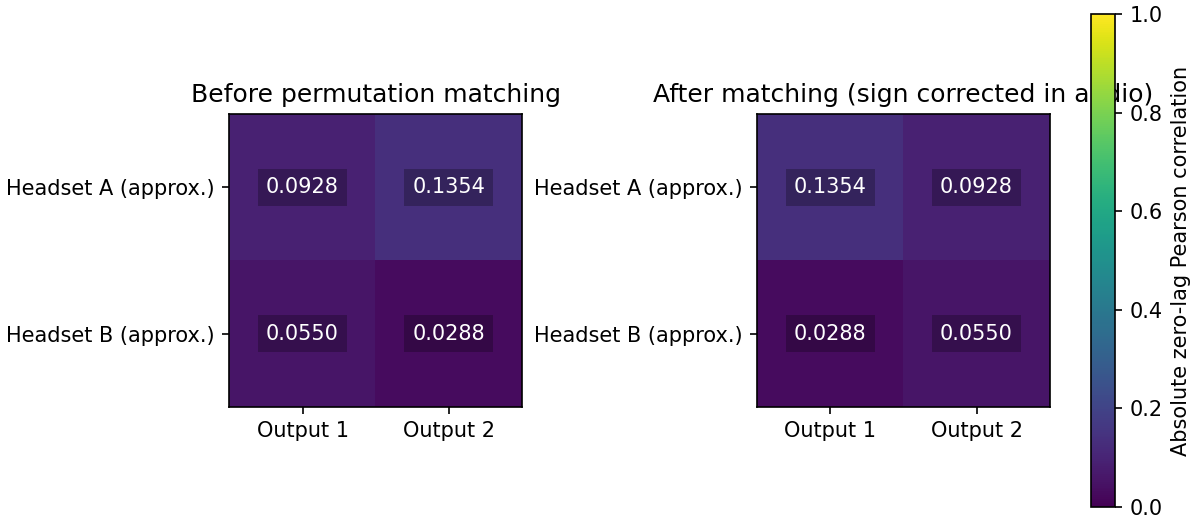

ICA hoạt động tốt ở mô hình trộn tức thời, suy giảm mạnh khi A gần suy biến và có noise. Với phòng họp thật, hội tụ chưa chứng minh tách sạch; reverberation và delay không được mô hình tức thời biểu diễn đầy đủ.

In [6]:
show('separation/controlled_summary')
show('separation/real_23s_correlation')
display(Markdown('ICA hoạt động tốt ở mô hình trộn tức thời, suy giảm mạnh khi A gần suy biến và có noise. '
    'Với phòng họp thật, hội tụ chưa chứng minh tách sạch; reverberation và delay không được mô hình tức thời biểu diễn đầy đủ.'))

### 6. Báo cáo và sản phẩm nộp

Báo cáo tự lấy số liệu vừa chạy, có công thức, tham số, ba kết luận có số liệu và câu trả lời cho 12 câu hỏi. Không tự gán điểm chất lượng nghe khi chưa có đánh giá nghe độc lập.

In [7]:
report = build_report(ROOT)
print('Report:',report)
print('Nguồn Markdown:',ROOT/'report.md')
print('Tổng hợp:',ROOT/'results/lab_summary.json')
display(Markdown('[Mở báo cáo PDF 6 trang](../report.pdf)'))

Report: /home/minh/Desktop/Speech-Audio-processing-lab/Lab05_2351260673_NguyenVanMinh/report.pdf
Nguồn Markdown: /home/minh/Desktop/Speech-Audio-processing-lab/Lab05_2351260673_NguyenVanMinh/report.md
Tổng hợp: /home/minh/Desktop/Speech-Audio-processing-lab/Lab05_2351260673_NguyenVanMinh/results/lab_summary.json


[Mở báo cáo PDF 6 trang](../report.pdf)